# U Gem velocity-plane emission reconstruction

## Problem
Recover all 144×144 signed velocity-plane emission samples from 28 real optical spectra. This is velocity tomography, not a sky image. Finite exposure, missing viewing angles, eclipse and variable flux make the inference conditional. Neither the original reconstruction nor its local reproduction is independent truth.


In [1]:
import os,sys,time,json,hashlib
from pathlib import Path
import numpy as np, scipy, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import prepare,SOURCE_TWO_PI
from src.physics_model import DopplerModel
from src.solvers import reconstruct
from src.generate_data import add_spectral_noise
from src.visualization import export_figure,image_panel
FIG=Path(os.environ['IMAGING_FIGURE_DIR'])
print(json.dumps(dict(python=sys.executable,numpy=np.__version__,scipy=scipy.__version__,backend=matplotlib.get_backend()),indent=2))
raw=dict(np.load(ROOT/'data/raw_data.npz',allow_pickle=False))
original=dict(np.load(ROOT/'notebooks/reference_outputs/original_fullprecision.npz',allow_pickle=False))
source_trace=dict(np.load(ROOT/'notebooks/reference_outputs/original_convergence.npz',allow_pickle=False))
def show(fig,name,numeric,caption):
    path=export_figure(fig,FIG,name,numeric,caption);display(Image(filename=str(path)));plt.close(fig)


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "backend": "Agg"
}


## Data
All 28 native 2048-sample spectra and author phases are retained. The common exposure width 0.03930 cycle comes from the author phase file; the paper describes 300/600-second observations but individual assignments cannot be verified here. Spectral units U have no established absolute calibration. The common width is an explicit acquisition approximation selected before inspecting reconstruction quality.


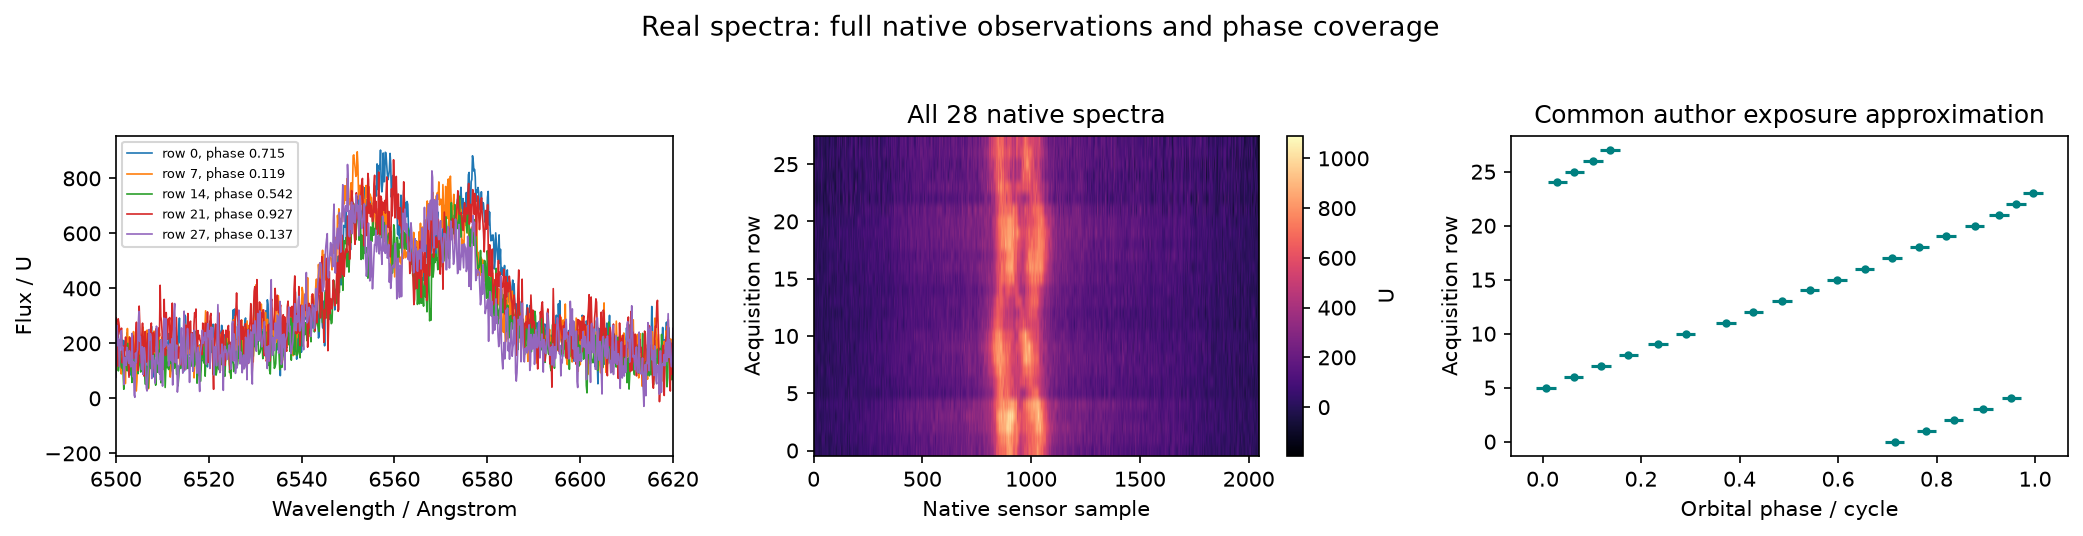

In [2]:
fig,ax=plt.subplots(1,3,figsize=(14,3.6))
wave=raw['wavelength'][0];flux=raw['spectrum'][0];phase=raw['orbital_phase'][0]
for i in [0,7,14,21,27]:ax[0].plot(wave[i],flux[i],label=f'row {i}, phase {phase[i]:.3f}',lw=.8)
ax[0].set_xlim(6500,6620);ax[0].set_xlabel('Wavelength / Angstrom');ax[0].set_ylabel('Flux / U');ax[0].legend(fontsize=6)
im=ax[1].imshow(flux,origin='lower',aspect='auto',cmap='magma',vmin=flux.min(),vmax=flux.max());ax[1].set_title('All 28 native spectra');fig.colorbar(im,ax=ax[1],label='U');ax[1].set_xlabel('Native sensor sample');ax[1].set_ylabel('Acquisition row')
ax[2].errorbar(phase,np.arange(28),xerr=.03930/2,fmt='o',ms=3,color='teal');ax[2].set_xlabel('Orbital phase / cycle');ax[2].set_ylabel('Acquisition row');ax[2].set_title('Common author exposure approximation')
show(fig,'figure1_data',dict(wavelength=wave,flux=flux,phase=phase,common_width=np.array(.03930)),'Real spectra: full native observations and phase coverage')


## Physics
At orbital angle $\theta$, radial velocity is $v_x\sin\theta-v_y\cos\theta$. Projection integrates a triangular profile between exposure endpoint velocities widened by a velocity pixel. Column-normalized $P$ acts on positive latent pixel flux $x$. The full output density is $(x-b)\Delta\nu/\Delta v^2$, where $b$ is the observation-derived flat background, $\Delta\nu$ is the spectral frequency step and $\Delta v$ the velocity-plane spacing. Output axes are $(v_y,v_x)$, all 144² samples remain present.

The baseline makes positive data without asserting absolute line positivity. Integrated non-eclipse spectra are normalized to their common mean. Five predetermined eclipse phases receive zero likelihood weight; the independent full-spectrum residual still includes them. Legacy nominal velocity constants and float32 projection storage are preserved. We do not reinterpret these approximations as exact calibration.


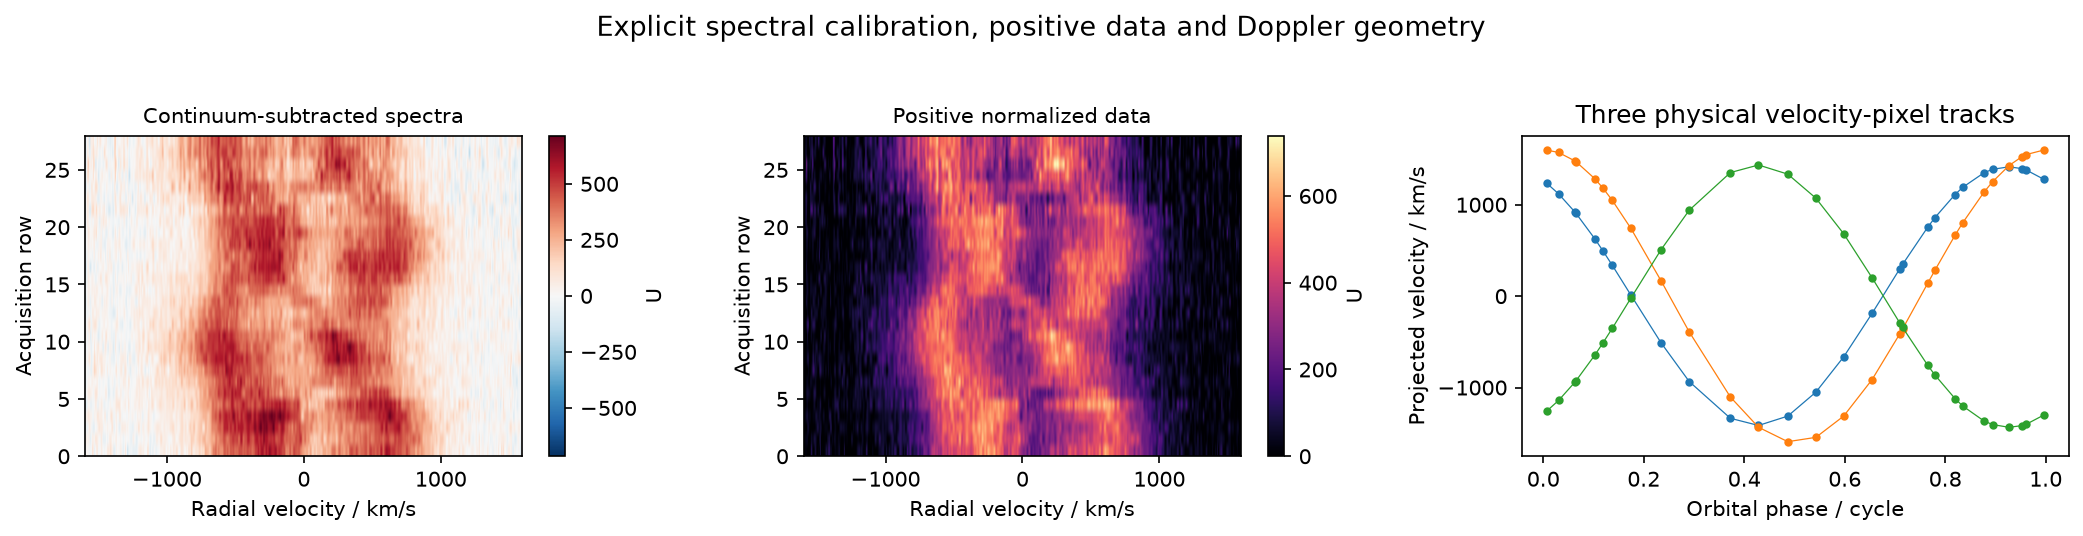

Projection: (13356, 16124) nonzeros: 13230264 geometry seconds: 2.7353066000068793


In [3]:
prepared=prepare(raw);start=time.perf_counter();model=DopplerModel(prepared);geometry_seconds=time.perf_counter()-start
state=model.initialize_data(prepared['line_spectra']);v=model.velocity/1e5
fig,ax=plt.subplots(1,3,figsize=(14,3.6))
im=image_panel(ax[0],prepared['line_spectra'],'Continuum-subtracted spectra',extent=[v[0],v[-1],0,28],signed=True);fig.colorbar(im,ax=ax[0],label='U')
positive=state['positive_data'].reshape(477,28).T
im=image_panel(ax[1],positive,'Positive normalized data',extent=[v[0],v[-1],0,28]);fig.colorbar(im,ax=ax[1],label='U')
order=np.argsort(phase)
for i in [model.n_pixels//4,model.n_pixels//2,3*model.n_pixels//4]:
    ax[2].plot(phase[order],((model.vx[i]*np.sin(model.phase)-model.vy[i]*np.cos(model.phase))/1e5)[order],'.-',lw=.6)
ax[2].set_xlabel('Orbital phase / cycle');ax[2].set_ylabel('Projected velocity / km/s');ax[2].set_title('Three physical velocity-pixel tracks')
for a in ax[:2]:a.set_xlabel('Radial velocity / km/s');a.set_ylabel('Acquisition row')
show(fig,'figure2_physics',dict(line_spectra=prepared['line_spectra'],positive_data=positive,velocity_km_s=v,weights=state['weights'].reshape(477,28).T,baseline=state['baseline_data']), 'Explicit spectral calibration, positive data and Doppler geometry')
print('Projection:',model.P_csc.shape,'nonzeros:',model.P_csc.nnz,'geometry seconds:',geometry_seconds)


## Method
We maximize $Q=H+\alpha S$, with $H=\sum_jw_j[y_j\log(Px)_j-(Px)_j]$ and $S=-\sum_i[x_i\log(x_i/q_i)-x_i+q_i]$, where $q=Gx$ is the reflected Gaussian floating default. The weights $w$ are predetermined likelihood weights, $y$ is the positive normalized data, and $\alpha=0.002$ selects the conditional field. Flux-projected gradients define the new scaled direction; analytic two-direction Newton curvature combines it with the previous direction. A positivity-limited step and fixed total-flux normalization follow. Convergence uses pre-update gradients; objective logs also describe pre-update fields, while the returned field is post-update.

The full original run and independent repeat preceded local extraction. We preserve its actual fixed-form normalization behavior (an unused THENWL assignment leaves WL zero), and its documented quantization. The active calculation below uses only local mathematics. The current-direction-only comparison is an explicit ablation, not an implementation of a different named method.


{
  "iterations": 27,
  "solve_seconds": 2.339959999997518,
  "ncc": 0.9999999999999997,
  "range_nrmse": 9.896093712720143e-10
}


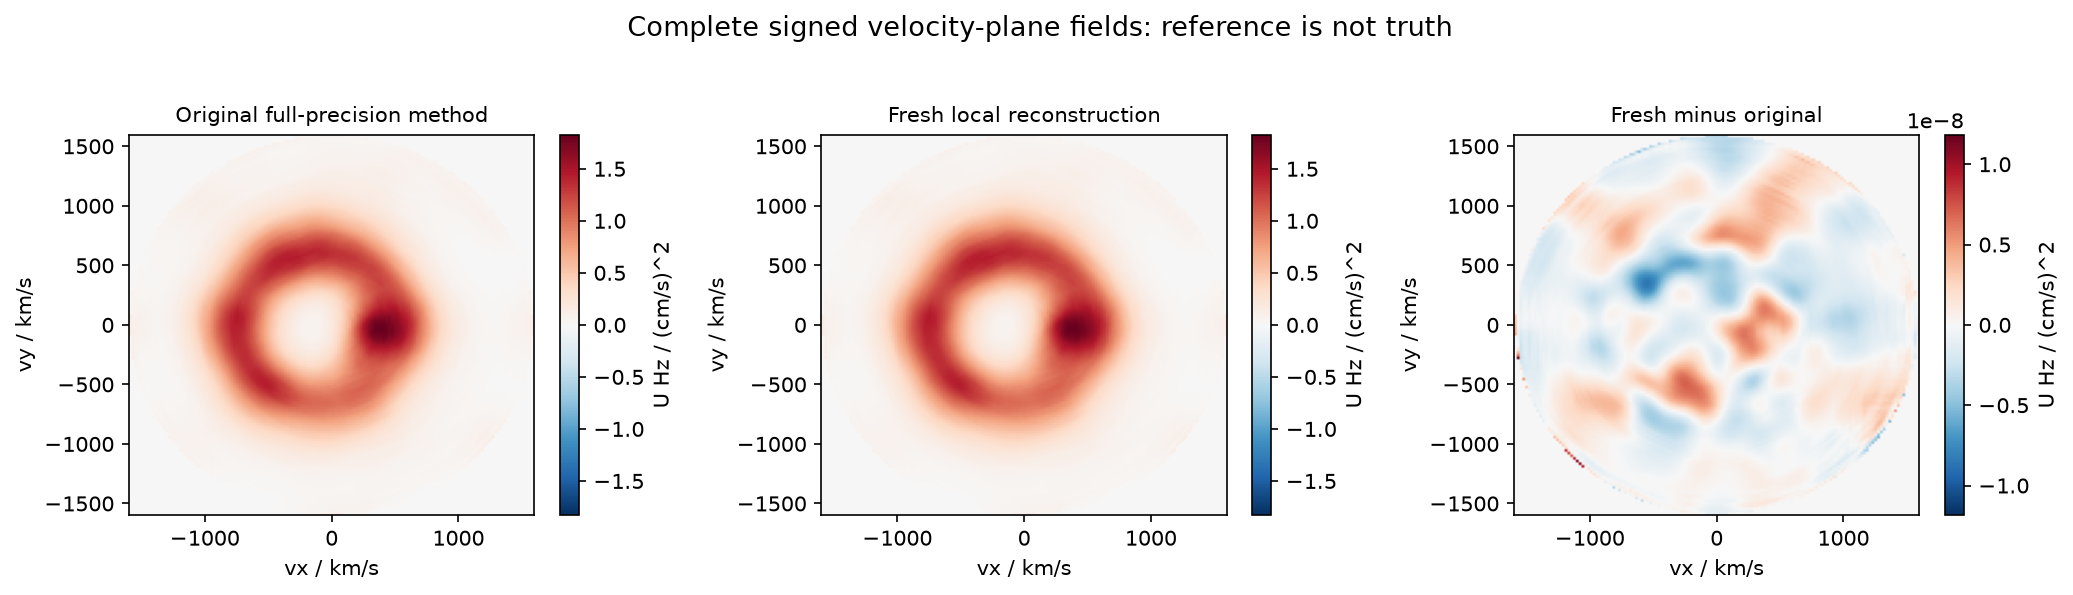

In [4]:
start=time.perf_counter();fresh=reconstruct(raw,model=model);solve_seconds=time.perf_counter()-start
field=fresh['reconstruction'][0];ref=original['reconstruction'][0]
error=float(np.sqrt(np.mean((field-ref)**2))/np.ptp(ref));cosine=float(np.vdot(field,ref)/(np.linalg.norm(field)*np.linalg.norm(ref)))
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh['reconstruction'])
print(json.dumps(dict(iterations=fresh['iterations'],solve_seconds=solve_seconds,ncc=cosine,range_nrmse=error),indent=2))
assert error<=7.691681073121665e-6 and cosine>=.999999
fig,ax=plt.subplots(1,3,figsize=(14,4));extent=[-model.va/1e5,model.va/1e5]*2
limit=max(abs(ref).max(),abs(field).max())
for a,arr,title in zip(ax,[ref,field,field-ref],['Original full-precision method','Fresh local reconstruction','Fresh minus original']):
    im=image_panel(a,arr,title,extent=extent,signed=True,limit=limit if 'minus' not in title else None);fig.colorbar(im,ax=a,label='U Hz / (cm/s)^2');a.set_xlabel('vx / km/s');a.set_ylabel('vy / km/s')
show(fig,'figure3_fields',dict(original=ref,fresh=field,difference=field-ref,velocity_axis=np.linspace(-model.va,model.va,144)/1e5),'Complete signed velocity-plane fields: reference is not truth')


## Results
The complete signed field is compared with an independently captured original result without alignment, amplitude fitting or weak-tail masking. The standard-method field tolerance was frozen from independent original reruns and native output precision. The full observation test below includes the five eclipse rows omitted from the likelihood. Strong residuals there express the stationary-emission model's limitations.

The paper's map/observed/computed/difference comparison is retained on every exposure row. We display acquisition rows directly rather than averaging them into phase bins, which would leave empty bins or merge exposures. Binary Roche/stream overlays require additional binary calibration and are not claimed here. Different objects in the paper are not additional bound datasets.


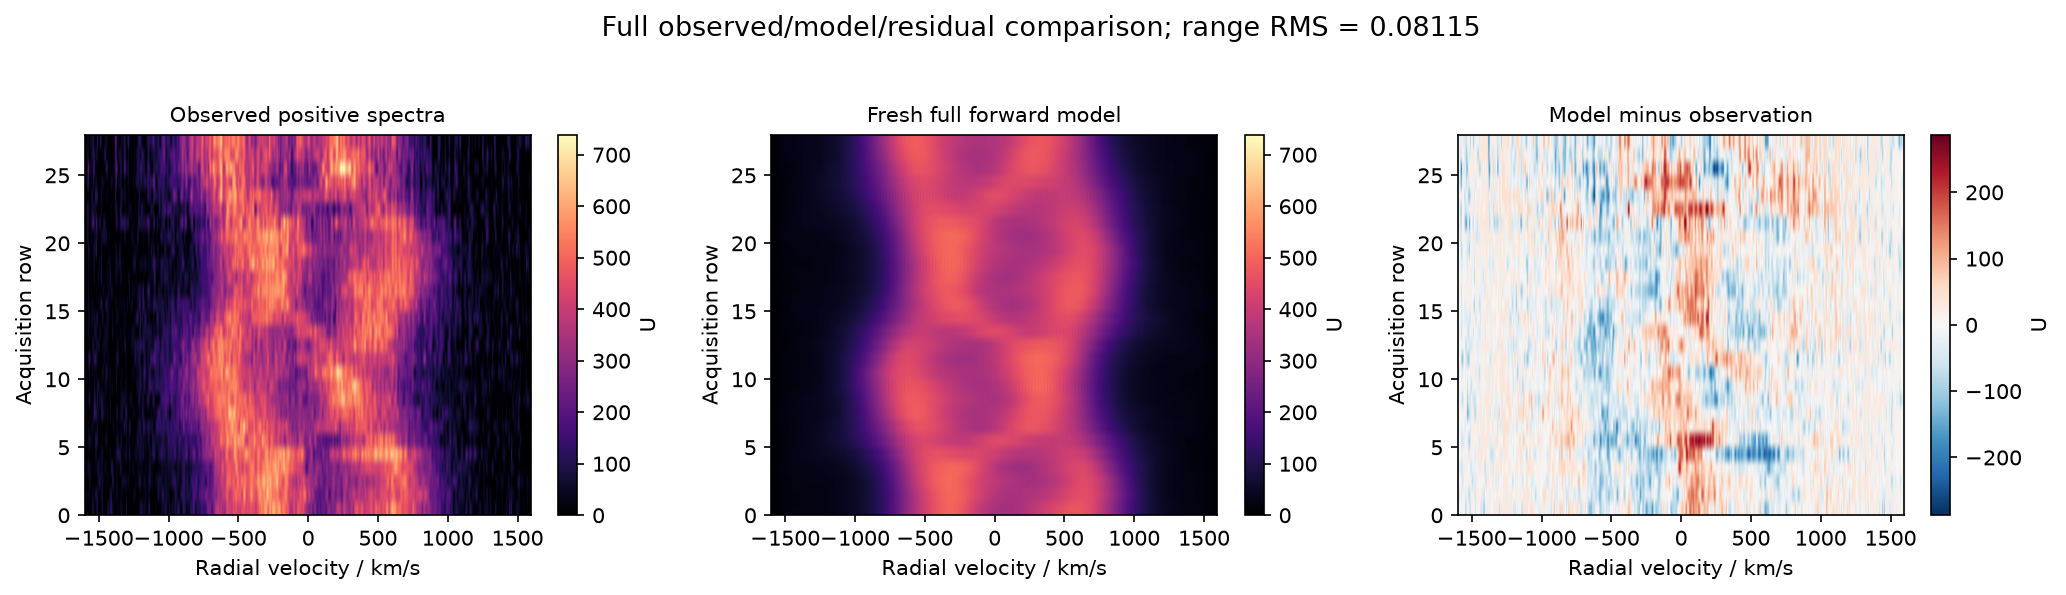

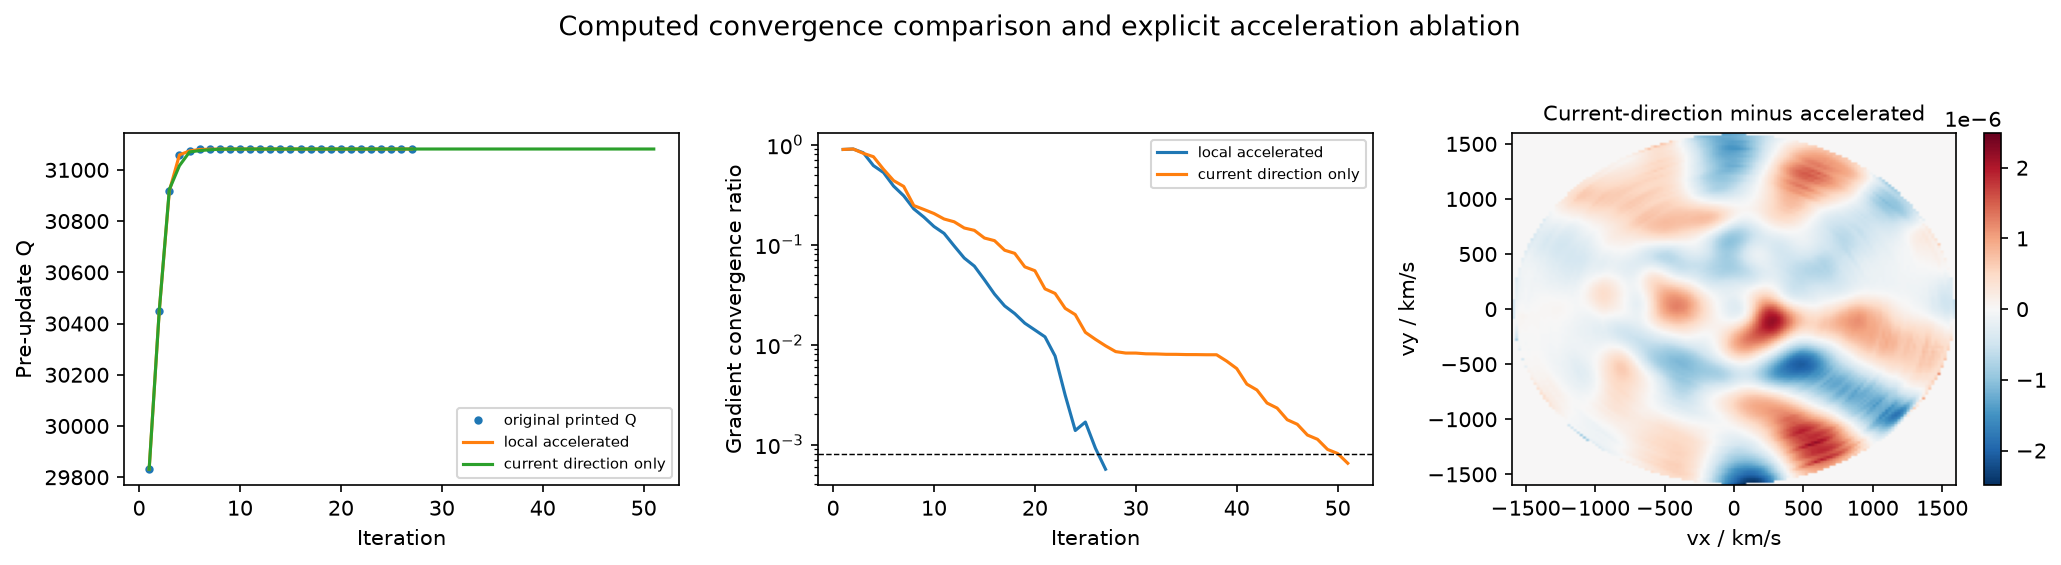

In [5]:
predicted=model.forward(fresh['positive_field']).reshape(477,28).T
residual=predicted-positive;forward_error=float(np.sqrt(np.mean(residual**2))/np.ptp(positive))
assert forward_error<=.08521206616956807
fig,ax=plt.subplots(1,3,figsize=(14,4));limit=max(positive.max(),predicted.max())
for a,arr,title in zip(ax,[positive,predicted,residual],['Observed positive spectra','Fresh full forward model','Model minus observation']):
    im=image_panel(a,arr,title,extent=[v[0],v[-1],0,28],signed='minus' in title,limit=None if 'minus' in title else limit);fig.colorbar(im,ax=a,label='U');a.set_xlabel('Radial velocity / km/s');a.set_ylabel('Acquisition row')
show(fig,'figure4_residual',dict(observed=positive,predicted=predicted,residual=residual,eclipse=state['blank_phases'],full_forward_range_rms=np.array(forward_error)),f'Full observed/model/residual comparison; range RMS = {forward_error:.5f}')
start=time.perf_counter();ablation=reconstruct(raw,model=model,current_direction_only=True);ablation_seconds=time.perf_counter()-start
fig,ax=plt.subplots(1,3,figsize=(14,3.8))
ax[0].plot(source_trace['iteration'],source_trace['objective'],'o',ms=3,label='original printed Q')
for result,label in [(fresh,'local accelerated'),(ablation,'current direction only')]:
    ax[0].plot([r['iteration'] for r in result['trace']],[r['objective'] for r in result['trace']],label=label)
    ax[1].semilogy([r['iteration'] for r in result['trace']],[r.get('convergence',np.nan) for r in result['trace']],label=label)
ax[0].set_ylabel('Pre-update Q');ax[1].set_ylabel('Gradient convergence ratio');ax[1].axhline(.0008,color='k',ls='--',lw=.7)
for a in ax[:2]:a.set_xlabel('Iteration');a.legend(fontsize=7)
im=image_panel(ax[2],ablation['reconstruction'][0]-field,'Current-direction minus accelerated',extent=extent,signed=True);fig.colorbar(im,ax=ax[2]);ax[2].set_xlabel('vx / km/s');ax[2].set_ylabel('vy / km/s')
show(fig,'figure5_acceleration',dict(source_iteration=source_trace['iteration'],source_objective=source_trace['objective'],fresh_objective=np.array([r['objective'] for r in fresh['trace']]),ablation_objective=np.array([r['objective'] for r in ablation['trace']]),ablation_field=ablation['reconstruction'],solve_seconds=np.array([solve_seconds,ablation_seconds])), 'Computed convergence comparison and explicit acceleration ablation')


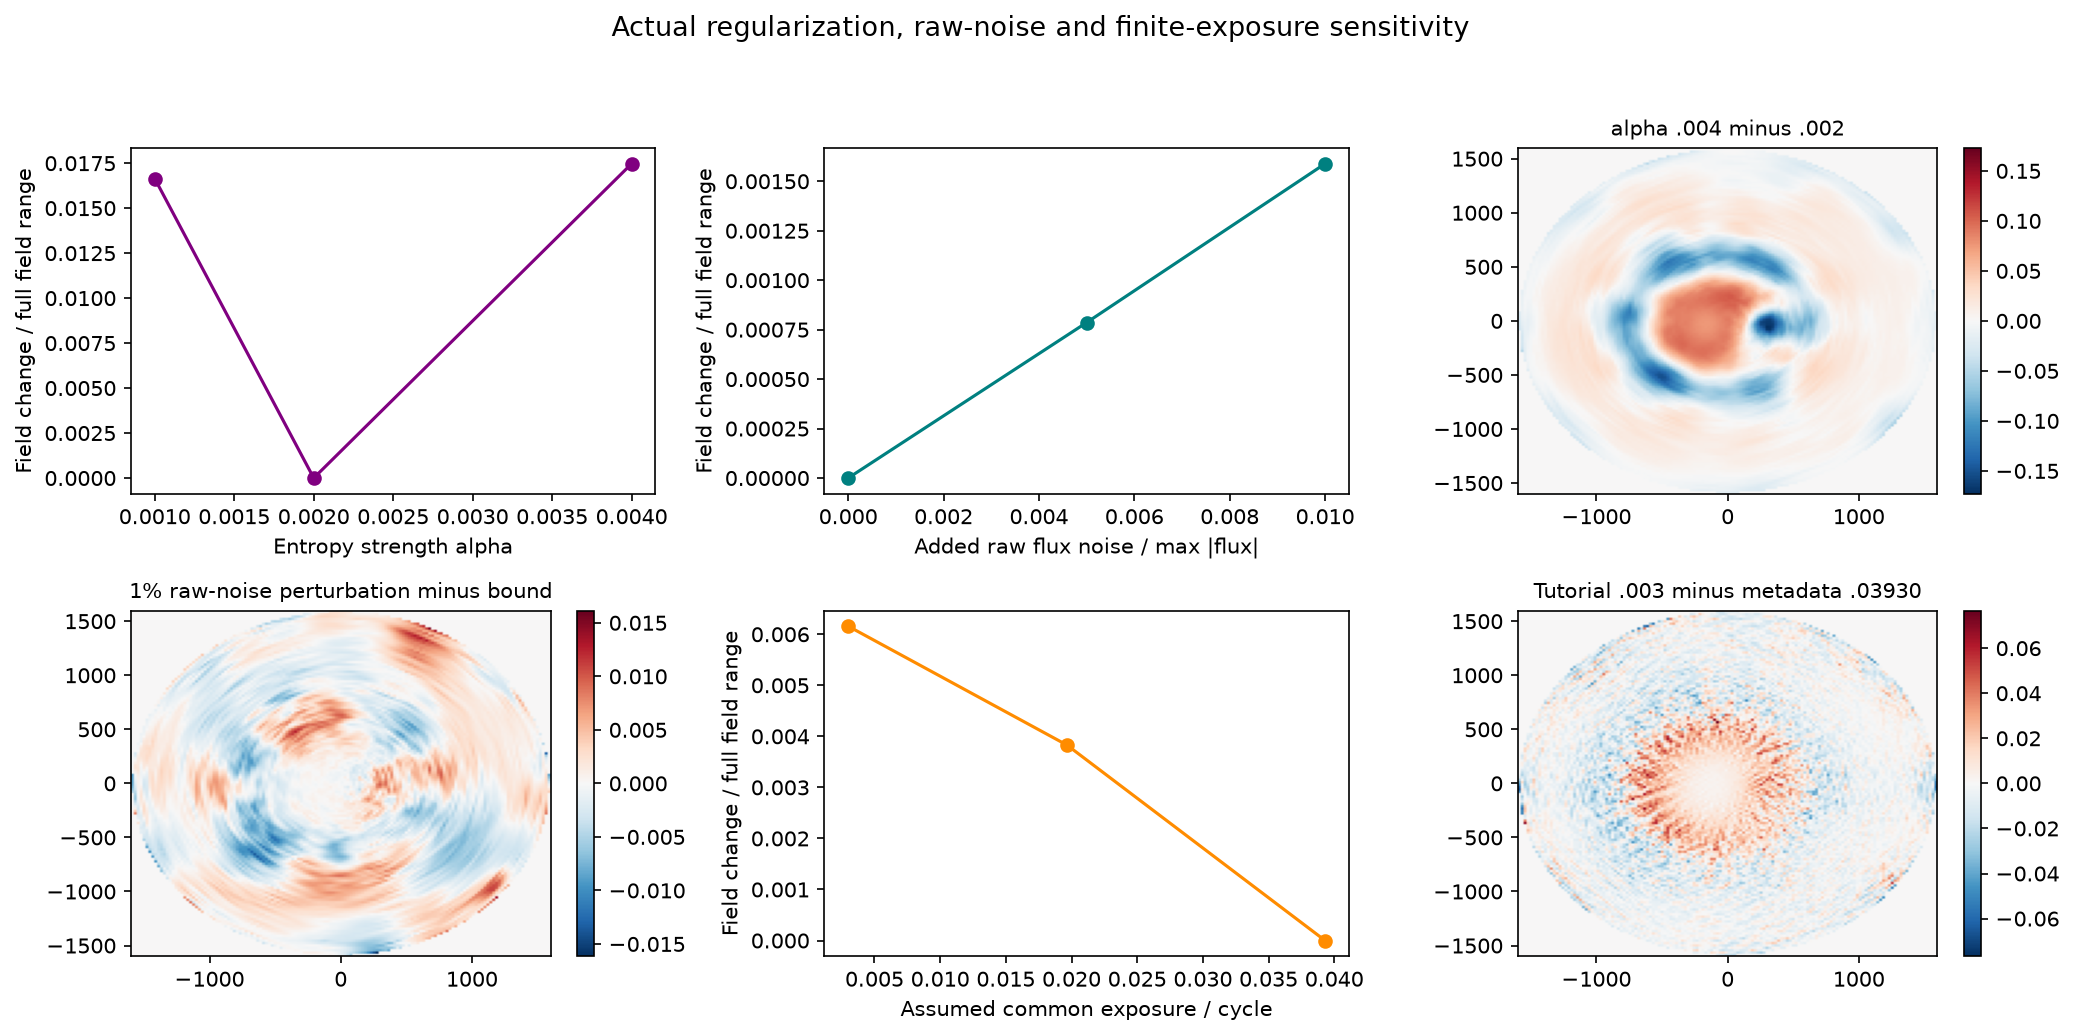

{
  "iterations": 27,
  "ncc": 0.9999999999999997,
  "range_nrmse": 9.896093712720143e-10,
  "forward_range_rms": 0.08115434872885191,
  "geometry_seconds": 2.7353066000068793,
  "solve_seconds": 2.339959999997518,
  "noise_seed": 123
}


In [6]:
alpha_values=[.001,.002,.004];alpha_fields=[];alpha_errors=[]
for alpha in alpha_values:
    r=reconstruct(raw,alpha=alpha,model=model);alpha_fields.append(r['reconstruction'][0]);alpha_errors.append(np.sqrt(np.mean((alpha_fields[-1]-field)**2))/np.ptp(field))
noise_levels=[0,.005,.01];noise_fields=[];noise_errors=[]
for level in noise_levels:
    r=reconstruct(add_spectral_noise(raw,level,seed=123),model=model);noise_fields.append(r['reconstruction'][0]);noise_errors.append(np.sqrt(np.mean((noise_fields[-1]-field)**2))/np.ptp(field))
fig,ax=plt.subplots(2,3,figsize=(14,7))
ax[0,0].plot(alpha_values,alpha_errors,'o-',color='purple');ax[0,0].set_xlabel('Entropy strength alpha');ax[0,0].set_ylabel('Field change / full field range')
ax[0,1].plot(noise_levels,noise_errors,'o-',color='teal');ax[0,1].set_xlabel('Added raw flux noise / max |flux|');ax[0,1].set_ylabel('Field change / full field range')
im=image_panel(ax[0,2],alpha_fields[-1]-field,'alpha .004 minus .002',extent=extent,signed=True);fig.colorbar(im,ax=ax[0,2])
im=image_panel(ax[1,0],noise_fields[-1]-field,'1% raw-noise perturbation minus bound',extent=extent,signed=True);fig.colorbar(im,ax=ax[1,0])
# Geometry variants are actual fresh calculations; release the main operator first.
del model;fresh.pop('model');ablation.pop('model');r.pop('model');import gc;gc.collect()
widths=[.003,.01965,.03930];width_fields=[];width_errors=[]
for width in widths:
    p={k:np.array(value,copy=True) for k,value in prepared.items()};p['phase_width_radians']=np.full(28,width*SOURCE_TWO_PI)
    variant=DopplerModel(p);result=reconstruct(raw,model=variant);width_fields.append(result['reconstruction'][0]);width_errors.append(np.sqrt(np.mean((width_fields[-1]-field)**2))/np.ptp(field));del result,variant;gc.collect()
ax[1,1].plot(widths,width_errors,'o-',color='darkorange');ax[1,1].set_xlabel('Assumed common exposure / cycle');ax[1,1].set_ylabel('Field change / full field range')
im=image_panel(ax[1,2],width_fields[0]-field,'Tutorial .003 minus metadata .03930',extent=extent,signed=True);fig.colorbar(im,ax=ax[1,2])
show(fig,'figure6_sensitivity',dict(alpha=np.array(alpha_values),alpha_fields=np.array(alpha_fields),alpha_error=np.array(alpha_errors),noise=np.array(noise_levels),noise_fields=np.array(noise_fields),noise_error=np.array(noise_errors),width=np.array(widths),width_fields=np.array(width_fields),width_error=np.array(width_errors)), 'Actual regularization, raw-noise and finite-exposure sensitivity')
summary=dict(iterations=fresh['iterations'],ncc=cosine,range_nrmse=error,forward_range_rms=forward_error,geometry_seconds=geometry_seconds,solve_seconds=solve_seconds,noise_seed=123)
(FIG/'notebook_measurements.json').write_text(json.dumps(summary,indent=2),encoding='utf8');print(json.dumps(summary,indent=2))


## Conclusion
The local accelerated maximum-entropy method reconstructs the complete signed velocity-plane field and reproduces the independently captured original calculation. Full forward residuals expose deviations from the stationary-emission approximation, including eclipse rows. Computed acceleration, entropy-strength, raw-noise and exposure-width experiments quantify conditional behavior rather than establish a unique physical map.

Absolute flux, individual exposure durations and independent velocity-map truth are unavailable. Agreement to numerical precision concerns this selected discretization and acquisition approximation. It does not imply equally accurate disk structure, a unique sky location or exact astrophysical phase-space emissivity.
